In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


(256, 256)


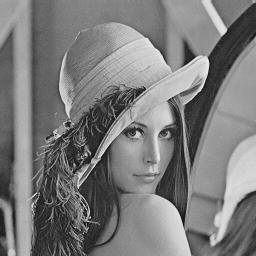

In [3]:
img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/lena256.jpg')
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gimg = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print(gimg.shape)
cv2_imshow(gimg)

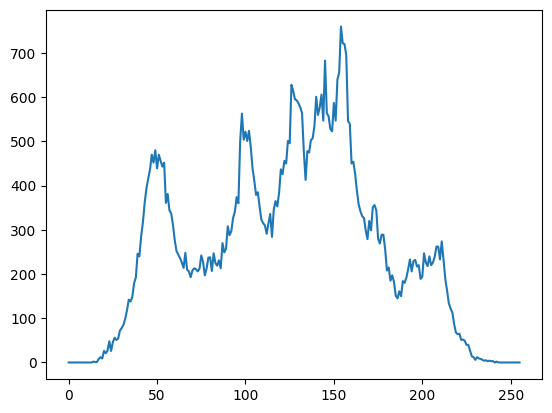

In [4]:
hist=cv2.calcHist([gimg],[0],None,[256],[0,256])
plt.plot(hist)

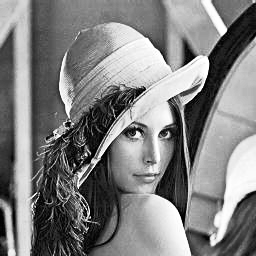

In [5]:
gOut=cv2.equalizeHist(gimg)
cv2_imshow(gOut)

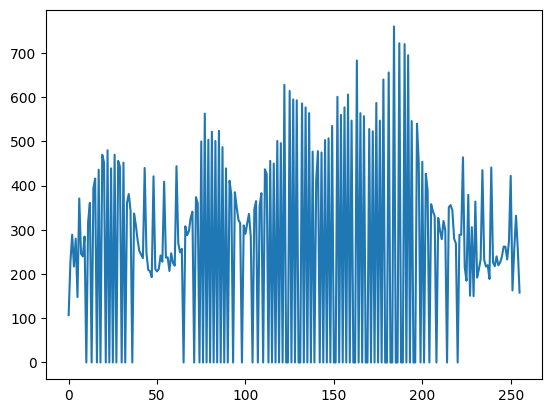

In [6]:
hist2=cv2.calcHist([gOut],[0],None,[256],[0,256])
plt.plot(hist2)

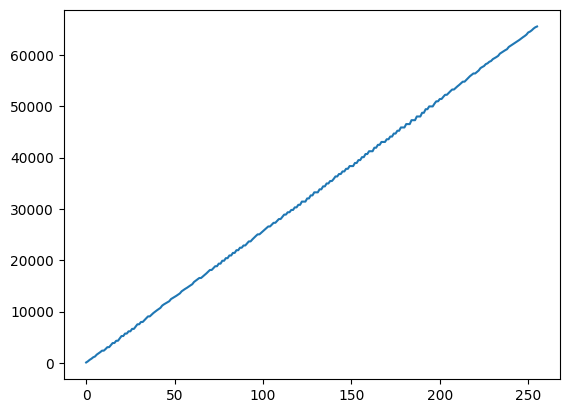

In [7]:
cumHist = hist2.copy()
for i in range(1, len(cumHist)):
  cumHist[i] = cumHist[i-1] + cumHist[i]

plt.plot(cumHist)

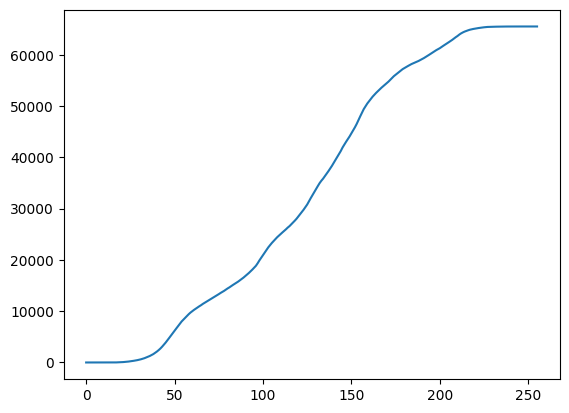

In [8]:
eqHist = hist.copy()

for i in range(len(eqHist)):
  eqHist[i] = eqHist[i - 1] + hist[i]

plt.plot(eqHist)

65536


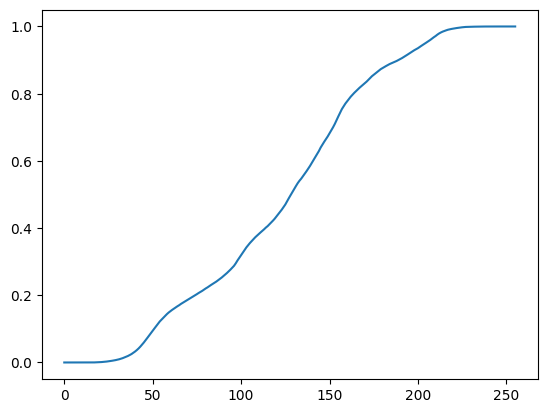

In [9]:
numOfPixels = np.int32(gimg.shape[0] * gimg.shape[1])
print(numOfPixels)
eqHist1 = eqHist/numOfPixels
plt.plot(eqHist1)

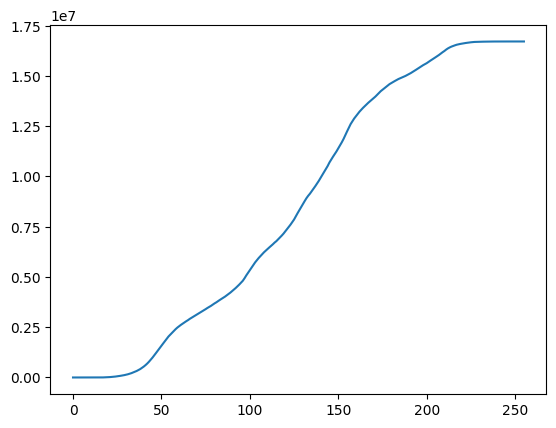

In [17]:
eqHist2 = eqHist * 255
plt.plot(eqHist2)

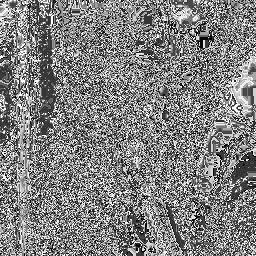

In [28]:
gOut1 = gimg.copy()
for i in range(gimg.shape[0]):
  for j in range(gimg.shape[1]):
    gOut1[i,j] = eqHist2[gimg[i,j]]
cv2_imshow(gOut1)

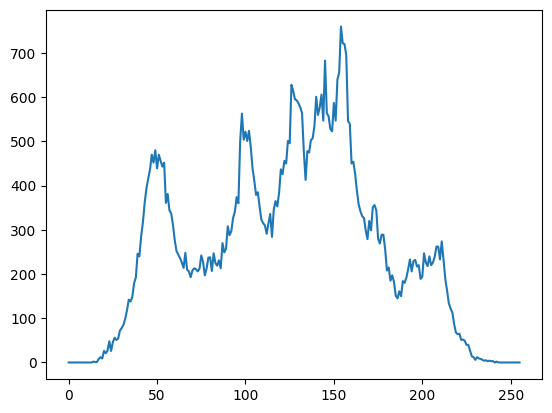

In [29]:
hist4 = cv2.calcHist([gOut2], [0], None, [256], [0, 256])
plt.plot(hist4)